Short-term RMSE: 0.005, Corr: 1.000


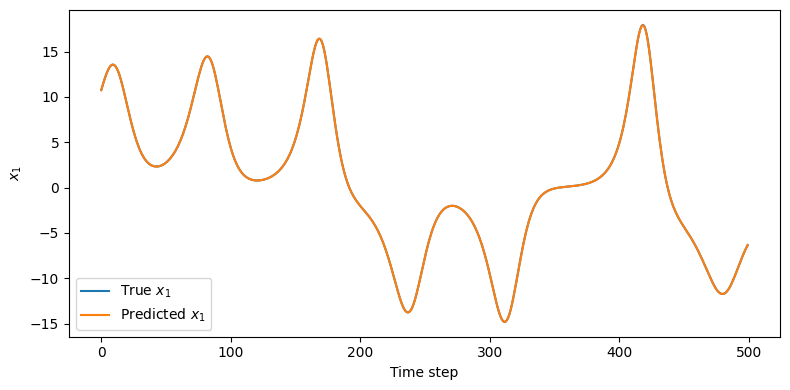

In [17]:
import torch, matplotlib.pyplot as plt

# -----------------------------
# 1. Lorenz–63 integrator
# -----------------------------
def lorenz63(xyz, sigma=10.0, rho=28.0, beta=8/3):
    x, y, z = xyz[..., 0], xyz[..., 1], xyz[..., 2]
    dx = sigma * (y - x)
    dy = x * (rho - z) - y
    dz = x * y - beta * z
    return torch.stack([dx, dy, dz], dim=-1)

def rk4_step(func, state, dt, **kwargs):
    k1 = func(state, **kwargs)
    k2 = func(state + 0.5 * dt * k1, **kwargs)
    k3 = func(state + 0.5 * dt * k2, **kwargs)
    k4 = func(state + dt * k3, **kwargs)
    return state + (dt / 6.0) * (k1 + 2*k2 + 2*k3 + k4)

def generate_lorenz63(n_steps=15000, dt=0.01, device="cpu"):
    state = torch.tensor([[1.0, 1.0, 1.0]], device=device)
    traj = [state]
    for _ in range(n_steps):
        state = rk4_step(lorenz63, state, dt)
        traj.append(state)
    return torch.cat(traj, dim=0)

# -----------------------------
# 2. Helper: delay embedding
# -----------------------------
def make_delay_matrix(v, tau, step=1):
    N = len(v) - tau * step
    X = torch.zeros((N, tau + 1))
    for i in range(N):
        X[i] = v[i : i + (tau + 1) * step : step]
    return X

# -----------------------------
# 3. Simple RBF kernel ridge regression
# -----------------------------
def rbf_kernel(X, Y, sigma):
    sqdist = torch.cdist(X, Y) ** 2
    return torch.exp(-0.5 * sqdist / sigma ** 2)

def kernel_ridge_regression(X_train, Y_train, X_test, sigma=1.0, lam=1e-6):
    K = rbf_kernel(X_train, X_train, sigma)
    I = torch.eye(K.shape[0])
    alpha = torch.linalg.solve(K + lam * I, Y_train)
    K_cross = rbf_kernel(X_test, X_train, sigma)
    return K_cross @ alpha

# -----------------------------
# 4. Generate data and train
# -----------------------------
dt = 0.01
traj = generate_lorenz63(n_steps=12000, dt=dt)
v = traj[:, 0]          # first coordinate

burnin = 500
train_N = 6000
test_N = 2000
tau = 12                # embedding dimension (Takens)
step = 1                # delay spacing

v_train = v[burnin : burnin + train_N + tau + 1]
v_test  = v[burnin + train_N : burnin + train_N + test_N + tau + 1]

X_train = make_delay_matrix(v_train, tau, step)
Y_train = v_train[tau:]           # <-- FIX: remove +1

X_test  = make_delay_matrix(v_test, tau, step)
Y_true  = v_test[tau:] 

# Normalize inputs and outputs
xmean, xstd = X_train.mean(0), X_train.std(0)
Xn = (X_train - xmean) / xstd
Xn_test = (X_test - xmean) / xstd
ymean, ystd = Y_train.mean(), Y_train.std()
Yn = (Y_train - ymean) / ystd

# -----------------------------
# 5. Train & predict
# -----------------------------
sigma = 0.8
lam = 1e-4
Y_pred = kernel_ridge_regression(Xn, Yn, Xn_test, sigma=sigma, lam=lam)
Y_pred = ymean + ystd * Y_pred  # de-normalize

# -----------------------------
# 6. Evaluate
# -----------------------------
rmse = torch.sqrt(torch.mean((Y_pred - Y_true) ** 2))
corr = torch.corrcoef(torch.stack([Y_pred, Y_true]))[0,1]
print(f"Short-term RMSE: {rmse:.3f}, Corr: {corr:.3f}")

# -----------------------------
# 7. Short-horizon forecast
# -----------------------------
plt.figure(figsize=(8,4))
plt.plot(Y_true[:500].cpu(), label="True $x_1$")
plt.plot(Y_pred[:500].detach().cpu(), label="Predicted $x_1$")
plt.xlabel("Time step")
plt.ylabel("$x_1$")
plt.legend(); plt.tight_layout()
plt.show()

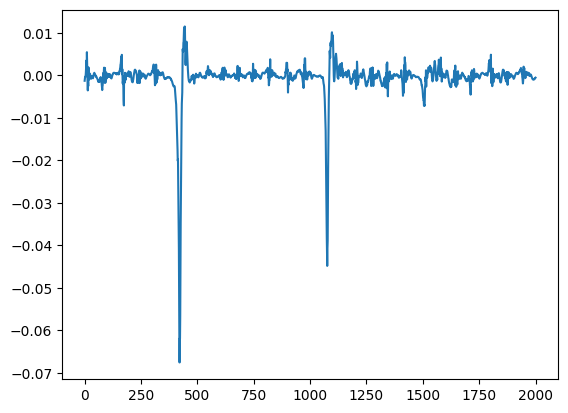

In [18]:
plt.plot(Y_pred.detach()-Y_true.detach())

RMSE: 3.775, Corr: 0.880


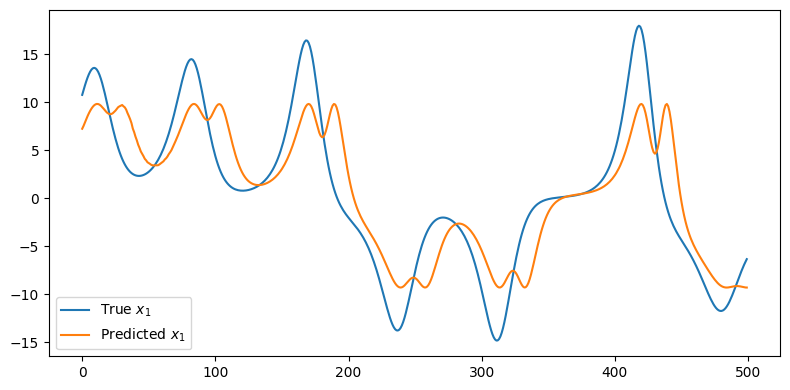

In [19]:
# ==========================================
# Advanced Mori–Zwanzig-inspired kernel
# ==========================================
def G_MATRIX(V, W, S, T, sigma_F=1.0, sigma_K1=1.0, sigma_K2=1.0):
    """
    Compute Gram matrix G((V,S), (W,T)) for Mori–Zwanzig-inspired kernel.
    V, W, S, T : tensors of shape (N, τ+1)
    """
    v_exp = V[:, None, :]        # (N, 1, τ+1)
    w_exp = W[None, :, :]        # (1, M, τ+1)
    s_exp = S[:, None, :]
    t_exp = T[None, :, :]

    # Direct similarity of the current observable (v0, w0)
    G_F = torch.exp(-0.5 * (v_exp[..., 0] - w_exp[..., 0]) ** 2 / sigma_F ** 2)

    # Reverse histories for time-correlation part
    v_flip = torch.flip(v_exp, dims=[-1])
    w_flip = torch.flip(w_exp, dims=[-1])

    # Compute Gaussian similarities between time coordinates
    K1 = torch.exp(-0.5 * (s_exp.unsqueeze(-2) - t_exp.unsqueeze(-3)) ** 2 / sigma_K1 ** 2)
    # and between the past states
    K2 = torch.exp(-0.5 * (v_flip.unsqueeze(-2) - w_flip.unsqueeze(-3)) ** 2 / sigma_K2 ** 2)

    # Combine via tensor contraction (sum over τ+1 x τ+1)
    sum_term = torch.sum(K1 * K2, dim=(-2, -1))

    return G_F + sum_term

def kernel_ridge_regression_mz(X_train, S_train, Y_train,
                               X_test, S_test,
                               sigma_F=0.3, sigma_K1=0.5, sigma_K2=0.4,
                               lam=1e-5):
    N = X_train.shape[0]
    I = torch.eye(N, device=X_train.device)

    # Training Gram matrix
    K_train = G_MATRIX(X_train, X_train, S_train, S_train,
                       sigma_F, sigma_K1, sigma_K2)
    A = K_train + lam * I

    # Solve for weights
    alpha = torch.linalg.solve(A, Y_train.view(-1, 1))

    # Cross Gram matrix (test vs. train)
    K_cross = G_MATRIX(X_test, X_train, S_test, S_train,
                       sigma_F, sigma_K1, sigma_K2)
    Y_pred = (K_cross @ alpha).squeeze()

    return Y_pred

def make_time_delay_matrix(times, tau, step=1):
    N = len(times) - tau * step
    T = torch.zeros((N, tau + 1))
    for i in range(N):
        T[i] = times[i : i + (tau + 1) * step : step]
    return T

# Assume you’ve already generated `traj`, `v`, etc. as before
burnin = 500
train_N = 6000
test_N = 2000
dt = 0.01
tau = 12
step = 1

v_train = v[burnin : burnin + train_N + tau + 1]
v_test  = v[burnin + train_N : burnin + train_N + test_N + tau + 1]
t_train = dt * torch.arange(burnin, burnin + train_N + tau + 1)
t_test  = dt * torch.arange(burnin + train_N, burnin + train_N + test_N + tau + 1)

X_train = make_delay_matrix(v_train, tau, step)
X_test  = make_delay_matrix(v_test, tau, step)
S_train = make_time_delay_matrix(t_train, tau, step)
S_test  = make_time_delay_matrix(t_test, tau, step)
Y_train = v_train[tau:]    # next step
Y_true  = v_test[tau:]

# Normalize inputs and outputs
xmean, xstd = X_train.mean(0), X_train.std(0)
X_train = (X_train - xmean) / xstd
X_test  = (X_test - xmean) / xstd
ymean, ystd = Y_train.mean(), Y_train.std()
Y_train_n = (Y_train - ymean) / ystd

# Train and predict with advanced kernel
Y_pred_n = kernel_ridge_regression_mz(X_train, S_train, Y_train_n,
                                      X_test, S_test,
                                      sigma_F=2.3, sigma_K1=0.5, sigma_K2=0.2, lam=1e-1)

Y_pred = ymean + ystd * Y_pred_n

# Evaluate
rmse = torch.sqrt(torch.mean((Y_pred - Y_true) ** 2))
corr = torch.corrcoef(torch.stack([Y_pred, Y_true]))[0, 1]
print(f"RMSE: {rmse:.3f}, Corr: {corr:.3f}")

plt.figure(figsize=(8,4))
plt.plot(Y_true[:500], label="True $x_1$")
plt.plot(Y_pred[:500].detach(), label="Predicted $x_1$")
plt.legend(); plt.tight_layout(); plt.show()